# **Nama Anggota Kelompok**
- Ranya Salma Aqila
- Raihan Fawwaz Naufal
- Naila Hariri
- Rubben Siahaan

# **Deskripsi Proyek Kelompok**
Proyek final ini menggunakan dataset Coffee Shop Transaction buat analisis clustering pakai K-Means. Tujuannya buat mengelompokkan pelanggan berdasarkan transaksi mereka, seperti total penjualan, jumlah produk, dan harga unit. Silhouette Score digunakan buat ngecek kualitas clustering, supaya hasilnya jelas dan terpisah dengan baik.

Setelah clustering, kita analisis kelompok pelanggan berdasarkan pola pembelian, seperti pelanggan dengan pembelian tinggi atau yang sering beli produk premium. Untuk nambah wawasan, kita pakai Large Language Model (LLM) buat menjelaskan otomatis tiap cluster dan memberikan insight lebih dalam soal karakteristik kelompok pelanggan.

# **Langkah 1: Import Library yang Dibutuhkan**
Di langkah pertama, kita perlu mengimpor berbagai library atau pustaka yang diperlukan untuk menganalisis data dan membuat model machine learning:

- Pandas digunakan untuk mengolah data.
- Matplotlib dan Seaborn digunakan untuk menggambar grafik dan visualisasi.
- Scikit-learn digunakan untuk preprocessing (persiapan data) dan algoritma KMeans untuk clustering.
- LangChain digunakan untuk menghubungkan model AI (misalnya Google Gemini AI) yang membantu kita dalam memberikan wawasan lebih lanjut tentang hasil clustering.
- Tabulate membantu menampilkan data dalam bentuk tabel yang lebih rapi.

In [ ]:
# Import Library yang Dibutuhkan
import pandas as pd  # Untuk manipulasi data
import matplotlib.pyplot as plt  # Untuk visualisasi grafik
import seaborn as sns  # Untuk visualisasi yang lebih interaktif

from sklearn.preprocessing import StandardScaler  # Untuk normalisasi data
from sklearn.cluster import KMeans  # Algoritma clustering K-Means
from sklearn.metrics import silhouette_score  # Untuk evaluasi clustering
from langchain_google_genai.chat_models import ChatGoogleGenerativeAI  # Untuk integrasi Gemini AI
from langchain.prompts import ChatPromptTemplate  # Untuk menyiapkan prompt Chat
from langchain.chains import LLMChain  # Untuk menjalankan model
from IPython.display import display  # Untuk menampilkan data dalam format yang lebih rapih
from tabulate import tabulate  # Untuk membuat tabel yang lebih rapi
from getpass import getpass

# **Langkah 2: Memuat Dataset**
Di langkah ini, kita mengunggah file dataset (file yang berisi data transaksi) dan membacanya ke dalam DataFrame (struktur data yang digunakan oleh Pandas). Pastikan dataset yang kita gunakan sudah benar dan bisa dibaca oleh program.

- Dataset bisa berbentuk file CSV atau Excel.

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/FINAL PROJECT MSIB 7 CELERATES/coffeeshop_transactions_2023.csv')  # Memuat dataset dari file CSV

In [ ]:
# Menampilkan 5 baris pertama dari dataset untuk memastikan data berhasil dimuat.
df.head()

,transaction_date,product_name,unit_price,total_qty,city,discount%
0,2023-11-27,Espresso,25000,3,Jakarta,20
1,2023-12-13,Cappuccino,30000,1,Bandung,5
2,2023-11-28,Latte,35000,5,Yogyakarta,15
3,2023-07-24,Espresso,25000,1,Jakarta,20
4,2023-06-19,Sandwich,45000,5,Bandung,0


In [ ]:
 # Mengecek dimensi dataset (jumlah baris, jumlah kolom)
df.shape

(750, 6)

# **Langkah 3: Menampilkan Informasi Dataset**
Setelah dataset berhasil dimuat, kita perlu mengecek informasi dasar dari data yang kita miliki:

- df.info() untuk melihat tipe data dan jumlah data yang tidak kosong di tiap kolom.
- df.describe() untuk melihat statistik deskriptif dari data (seperti rata-rata, nilai minimum, maksimum, dsb).
- df.isnull().sum() untuk mengecek apakah ada data yang hilang.
- df.duplicated().sum() untuk mengecek apakah ada data yang duplikat (sama persis).


In [ ]:
df.info()  # Menampilkan informasi dataset (jumlah entri, tipe data)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   transaction_date  750 non-null    object
 1   product_name      750 non-null    object
 2   unit_price        750 non-null    int64 
 3   total_qty         750 non-null    int64 
 4   city              750 non-null    object
 5   discount%         750 non-null    int64 
dtypes: int64(3), object(3)
memory usage: 35.3+ KB


In [ ]:
df.describe()  # Statistik deskriptif

,unit_price,total_qty,discount%
count,750.000000,750.000000,750.000000
mean,31938.666667,3.090667,10.073333
std,10253.084375,1.427292,7.020946
min,15000.000000,1.000000,0.000000
25%,25000.000000,2.000000,5.000000
50%,30000.000000,3.000000,10.000000
75%,40000.000000,4.000000,15.000000
max,50000.000000,5.000000,20.000000


In [ ]:
df.isnull().sum()  # Mengecek missing values

,0
transaction_date,0
product_name,0
unit_price,0
total_qty,0
city,0
discount%,0


In [ ]:
df.duplicated().sum()  # Mengecek jumlah data duplikat

0

# **Langkah 4: Preprocessing dan Invoke pada Data**
Di sini kita melakukan beberapa pemrosesan data agar data siap untuk analisis:

1. Menghapus data duplikat dan nilai kosong (NaN).
2. Mengubah kolom tanggal (seperti transaction_date) ke format datetime agar bisa diproses lebih lanjut.

3. Menambahkan kolom baru seperti:
- total_sales: Menghitung total penjualan (harga unit x jumlah produk).
- month: Mengambil bulan dari tanggal transaksi.
- day_of_week: Menentukan hari dalam seminggu berdasarkan tanggal transaksi.
4. Penanganan NaN - Menggunakan dropna() atau fillna() pada kolom penting seperti unit_price, total_qty, dan total_sales.
5. Normalisasi data numerik menggunakan StandardScaler, agar data dari berbagai kolom memiliki rentang nilai yang sama.

In [ ]:
# Menghapus duplikat jika ada
df = df.drop_duplicates()  # Menghapus data duplikat

In [ ]:
# Mengonversi kolom 'transaction_date' menjadi tipe datetime jika belum ada
df['transaction_date'] = pd.to_datetime(df['transaction_date'], errors='coerce')  # Mengubah ke datetime, jika ada kesalahan akan menjadi NaT

In [ ]:
# Hapus nilai negatif atau nol di kolom 'unit_price' dan 'total_qty'
df = df[(df['unit_price'] > 0) & (df['total_qty'] > 0)]

In [ ]:
# Memastikan kolom 'total_sales' ada, jika belum ada hitung menggunakan unit_price dan total_qty
if 'total_sales' not in df.columns:
    df['total_sales'] = df['unit_price'] * df['total_qty'] # Menghitung total sales sebagai produk dari harga satuan dan jumlah pembelian

In [ ]:
# # Mengganti nilai kosong (NaN) dengan rata-rata di kolom terkait
# Tujuannya adalah untuk memastikan tidak ada data kosong yang mengganggu proses analisis
df['total_sales'] = df['total_sales'].fillna(df['total_sales'].mean())  # Mengganti NaN pada 'total_sales' dengan rata-rata
df['unit_price'] = df['unit_price'].fillna(df['unit_price'].mean())  # Mengganti NaN pada 'unit_price' dengan rata-rata
df['total_qty'] = df['total_qty'].fillna(df['total_qty'].mean())  # Mengganti NaN pada 'total_qty' dengan rata-rata

# Menambahkan kolom baru:
- 'total_sales': Total penjualan = unit_price * total_qty
- 'month': Bulan dari tanggal transaksi
- 'day_of_week': Hari dalam minggu dari tanggal transaksi


In [ ]:
# Menambahkan kolom baru setelah pengisian NaN
df['month'] = df['transaction_date'].dt.month  # Mengambil bulan dari tanggal transaksi
df['day_of_week'] = df['transaction_date'].dt.dayofweek  # Menentukan hari dalam seminggu berdasarkan tanggal transaksi

In [ ]:
# Normalisasi data numerik menggunakan StandardScaler
numeric_features = ['unit_price', 'total_qty']
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])  # Normalisasi data numerik

In [ ]:
# Menampilkan hasil setelah preprocessing
print(f"Data setelah preprocessing:\n{df.head()}")

Data setelah preprocessing:
  transaction_date product_name  unit_price  total_qty        city  discount%  \
0       2023-11-27     Espresso   -0.677191  -0.063566     Jakarta         20   
1       2023-12-13   Cappuccino   -0.189207  -1.465756     Bandung          5   
2       2023-11-28        Latte    0.298776   1.338624  Yogyakarta         15   
3       2023-07-24     Espresso   -0.677191  -1.465756     Jakarta         20   
4       2023-06-19     Sandwich    1.274743   1.338624     Bandung          0   

   total_sales  month  day_of_week  
0        75000     11            0  
1        30000     12            2  
2       175000     11            1  
3        25000      7            0  
4       225000      6            0  


# **Invoke Data(Pemanggilan Data)**

In [ ]:
# Memilih data yang memiliki total penjualan lebih tinggi dari rata-rata
avg_sales = df['total_sales'].mean()  # Rata-rata total penjualan
high_sales_products = df[df['total_sales'] > avg_sales]  # Memilih produk dengan penjualan lebih tinggi dari rata-rata
print("\nProduk dengan total penjualan lebih tinggi dari rata-rata:\n", high_sales_products)


Produk dengan total penjualan lebih tinggi dari rata-rata:
     transaction_date product_name  unit_price  total_qty               city  \
2         2023-11-28        Latte    0.298776   1.338624         Yogyakarta   
4         2023-06-19     Sandwich    1.274743   1.338624            Bandung   
5         2023-08-09    Americano   -1.165175   1.338624         Yogyakarta   
7         2023-01-06   Cappuccino   -0.189207   0.637529            Jakarta   
9         2023-05-13        Latte    0.298776   0.637529            Jakarta   
..               ...          ...         ...        ...                ...   
741       2023-02-03    Macchiato    0.005986   0.637529            Jakarta   
743       2023-11-27    Macchiato    0.005986   0.637529            Bandung   
744       2023-08-16         Cake    1.762727   0.637529  Tangerang Selatan   
745       2023-03-07     Sandwich    1.274743   1.338624  Tangerang Selatan   
749       2023-01-22     Espresso   -0.677191   1.338624         Yogya

In [ ]:
# Mengambil transaksi dengan diskon lebih dari 20%
high_discount = df[df['discount%'] > 20]  # Filter transaksi dengan diskon lebih dari 20%
print(f"\nJumlah Transaksi dengan Diskon > 20%: {len(high_discount)}")
print(high_discount.head())  # Menampilkan 5 baris pertama sebagai contoh


Jumlah Transaksi dengan Diskon > 20%: 0
Empty DataFrame
Columns: [transaction_date, product_name, unit_price, total_qty, city, discount%, total_sales, month, day_of_week]
Index: []


In [ ]:
# Mengambil transaksi untuk bulan Januari (month == 1)
january_sales = df[df['month'] == 1]  # Filter transaksi untuk bulan Januari
print(f"\nJumlah Transaksi untuk Bulan Januari: {len(january_sales)}")
print(january_sales.head())  # Menampilkan 5 baris pertama sebagai contoh


Jumlah Transaksi untuk Bulan Januari: 57
   transaction_date product_name  unit_price  total_qty               city  \
7        2023-01-06   Cappuccino   -0.189207   0.637529            Jakarta   
28       2023-01-13    Americano   -1.165175  -0.764661             Bekasi   
52       2023-01-23   Flat White   -0.189207  -1.465756            Jakarta   
55       2023-01-12    Americano   -1.165175   0.637529  Tangerang Selatan   
79       2023-01-15    Americano   -1.165175  -0.063566             Bekasi   

    discount%  total_sales  month  day_of_week  
7          10       120000      1            4  
28          0        40000      1            4  
52          0        30000      1            0  
55          5        80000      1            3  
79         20        60000      1            6  


# **Langkah 5: Eksplorasi Data - Visualisasi**
Pada langkah ini, kita melakukan visualisasi data untuk memahami pola-pola yang ada. Beberapa visualisasi yang kita buat adalah:

- Distribusi Transaksi per Kota: Menampilkan jumlah transaksi yang terjadi di setiap kota.
- Distribusi Transaksi per Produk: Menampilkan jumlah transaksi berdasarkan produk yang terjual.
- Distribusi Diskon: Menunjukkan sebaran diskon yang diterapkan pada transaksi.
- Distribusi Total Penjualan: Menampilkan distribusi total penjualan di seluruh dataset.


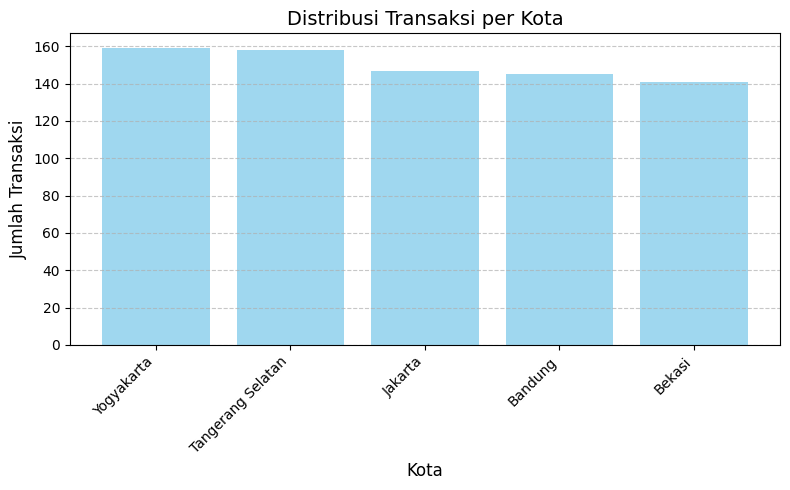

In [ ]:
# Visualisasi distribusi transaksi per kota
if 'city' in df.columns:
    plt.figure(figsize=(8, 5))
    city_counts = df['city'].value_counts()
    plt.bar(city_counts.index, city_counts.values, color='skyblue', alpha=0.8)
    plt.title('Distribusi Transaksi per Kota', fontsize=14)
    plt.xlabel('Kota', fontsize=12)
    plt.ylabel('Jumlah Transaksi', fontsize=12)
    plt.xticks(rotation=45, ha='right')  # Putar label kota agar lebih jelas
    plt.grid(axis='y', linestyle='--', alpha=0.7)  # Tambahkan grid horizontal
    plt.tight_layout()  # Tata letak grafik yang rapi
    plt.show()
else:
    print("Kolom 'city' tidak ditemukan. Pastikan preprocessing sudah benar.")

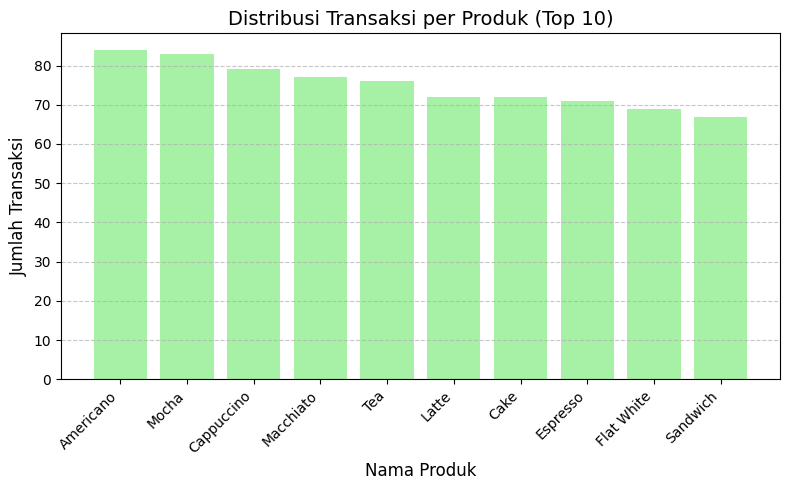

In [ ]:
# Visualisasi distribusi transaksi per produk
if 'product_name' in df.columns:
    plt.figure(figsize=(8, 5))
    product_counts = df['product_name'].value_counts().head(10)  # Ambil 10 produk teratas
    plt.bar(product_counts.index, product_counts.values, color='lightgreen', alpha=0.8)
    plt.title('Distribusi Transaksi per Produk (Top 10)', fontsize=14)
    plt.xlabel('Nama Produk', fontsize=12)
    plt.ylabel('Jumlah Transaksi', fontsize=12)
    plt.xticks(rotation=45, ha='right')  # Putar label produk agar lebih jelas
    plt.grid(axis='y', linestyle='--', alpha=0.7)  # Tambahkan grid horizontal
    plt.tight_layout()  # Tata letak grafik yang rapi
    plt.show()
else:
    print("Kolom 'product_name' tidak ditemukan. Pastikan preprocessing sudah benar.")

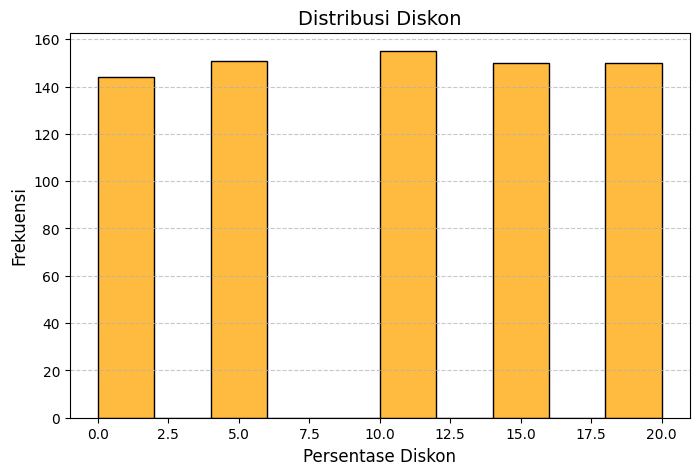

In [ ]:
# Visualisasi distribusi diskon
if 'discount%' in df.columns:
    plt.figure(figsize=(8, 5))
    # Use df['discount%'] to access the column data directly
    sns.histplot(df['discount%'], bins=10, kde=False, color='orange')
    plt.title('Distribusi Diskon', fontsize=14)
    plt.xlabel('Persentase Diskon', fontsize=12)
    plt.ylabel('Frekuensi', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()
else:
    print("Kolom 'discount%' tidak ditemukan. Pastikan preprocessing sudah benar.")

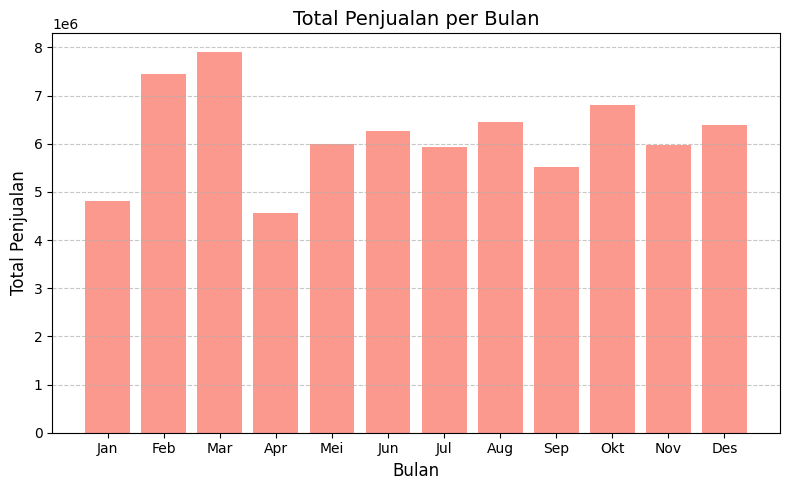

In [ ]:
# Visualisasi Total Penjualan per Bulan
if 'month' in df.columns and 'total_sales' in df.columns:
    # Hitung total penjualan per bulan
    monthly_sales = df.groupby('month')['total_sales'].sum()

    # Isi bulan yang hilang dengan nilai 0
    all_months = range(1, 13)  # Semua bulan dalam setahun
    monthly_sales = monthly_sales.reindex(all_months, fill_value=0)

    # Visualisasi total penjualan per bulan
    plt.figure(figsize=(8, 5))
    plt.bar(monthly_sales.index, monthly_sales.values, color='salmon', alpha=0.8)
    plt.title('Total Penjualan per Bulan', fontsize=14)
    plt.xlabel('Bulan', fontsize=12)
    plt.ylabel('Total Penjualan', fontsize=12)
    plt.xticks(monthly_sales.index, labels=['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Aug', 'Sep', 'Okt', 'Nov', 'Des'])
    plt.grid(axis='y', linestyle='--', alpha=0.7)  # Tambahkan grid untuk kejelasan
    plt.tight_layout()  # Pastikan tata letak grafik rapi
    plt.show()
else:
    print("Kolom 'month' atau 'total_sales' tidak ditemukan. Pastikan preprocessing sudah benar.")

# **Langkah 6: Menentukan Jumlah Cluster dengan Elbow Method**
Sekarang kita akan mencari berapa banyak cluster (kelompok) yang optimal. Caranya menggunakan Elbow Method:

- Kita coba jumlah cluster dari 1 hingga 10, lalu hitung nilai WCSS (Within-Cluster Sum of Squares), yang mengukur seberapa baik data dikelompokkan.
- Kita pilih jumlah cluster di mana grafik Elbow mulai “datar”, yang artinya tambahan cluster berikutnya tidak memberikan peningkatan yang signifikan.

In [ ]:
# Menggunakan metode Elbow untuk menentukan jumlah cluster optimal
# WCSS (Within-Cluster Sum of Squares) dihitung untuk jumlah cluster dari 1 hingga 10
# Langkah 6: Menentukan Jumlah Cluster dengan Elbow Method
wcss = []
for i in range(2, 11):  # Cluster dimulai dari 2
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(df[numeric_features])
    wcss.append(kmeans.inertia_)

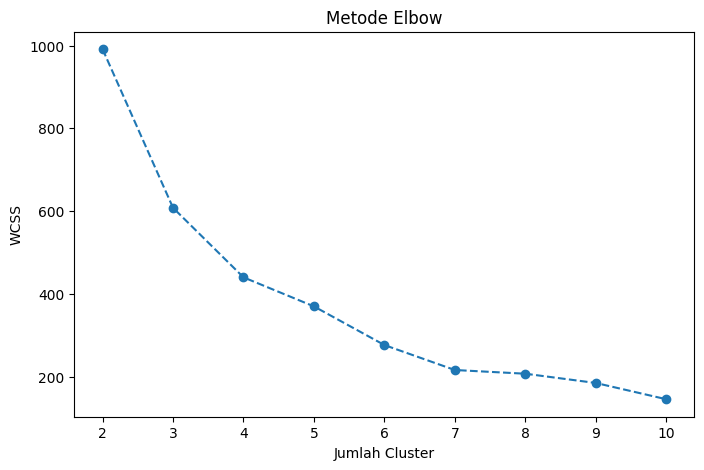

In [ ]:
# Visualisasi Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), wcss, marker='o', linestyle='--')
plt.title('Metode Elbow')
plt.xlabel('Jumlah Cluster')
plt.ylabel('WCSS')
plt.show()

# **Langkah 7: Evaluasi Silhouette Score untuk Berbagai Jumlah Cluster**
Setelah menggunakan Elbow Method, kita akan mengevaluasi model clustering menggunakan Silhouette Score untuk memastikan jumlah cluster yang dipilih sudah tepat:

- Silhouette Score memberi tahu seberapa baik data dikelompokkan dalam cluster yang sesuai. Nilai yang lebih tinggi menunjukkan hasil clustering yang lebih baik.

In [ ]:
silhouette_scores = []  # Untuk menyimpan hasil Silhouette Score

In [ ]:
best_score = -1
optimal_clusters = 0
for n_clusters in range(2, 11):  # Evaluasi untuk jumlah cluster 2 hingga 10
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    df['cluster'] = kmeans.fit_predict(df[numeric_features])

In [ ]:

    # Menghitung Silhouette Score untuk cluster yang diterapkan
    silhouette_avg = silhouette_score(df[numeric_features], df['cluster'])
    silhouette_scores.append((n_clusters, silhouette_avg))


In [ ]:
# Menampilkan hasil Silhouette Score untuk berbagai jumlah cluster
for n_clusters, score in silhouette_scores:
    print(f"Jumlah Cluster: {n_clusters}, Silhouette Score: {score:.2f}")

Jumlah Cluster: 10, Silhouette Score: 0.45


In [ ]:
# Tentukan jumlah cluster optimal berdasarkan nilai Silhouette Score terbaik
optimal_clusters = max(silhouette_scores, key=lambda x: x[1])[0]
print(f"Jumlah cluster optimal berdasarkan Silhouette Score: {optimal_clusters}")

Jumlah cluster optimal berdasarkan Silhouette Score: 10


# **Langkah 8: Clustering dengan K-Means**
Di sini, kita menggunakan KMeans untuk mengelompokkan data berdasarkan jumlah cluster yang sudah kita pilih sebelumnya:

- KMeans akan membagi data ke dalam beberapa kelompok (cluster) dan menambahkan hasilnya ke dalam kolom cluster di dataset.
- Hasil clustering ini kemudian kita visualisasikan untuk melihat sebaran data berdasarkan cluster.


In [ ]:
# Clustering dengan KMeans menggunakan jumlah cluster optimal
kmeans = KMeans(n_clusters=optimal_clusters, random_state=42)  # Menggunakan jumlah cluster optimal yang ditemukan sebelumnya
df['cluster'] = kmeans.fit_predict(df[numeric_features])  # Menambahkan hasil clustering ke kolom 'cluster'

In [ ]:
# Kembalikan data numerik ke skala asli untuk interpretasi
df[numeric_features] = scaler.inverse_transform(df[numeric_features])  # Inverse transform untuk kembali ke skala asli

In [ ]:
# Menampilkan hasil clustering
print(f"Jumlah cluster optimal: {optimal_clusters}")
print(df['cluster'].value_counts()) # Menampilkan jumlah data di setiap cluster

Jumlah cluster optimal: 10
cluster
9    123
0    100
5     98
4     88
3     70
2     69
7     55
1     55
6     48
8     44
Name: count, dtype: int64


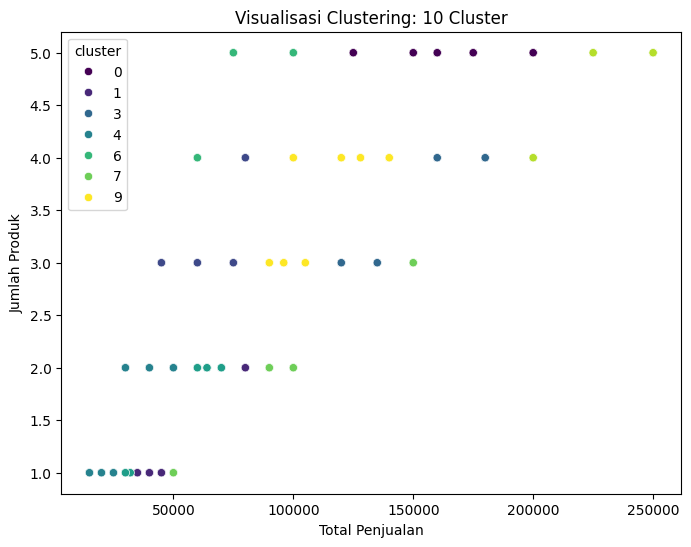

In [ ]:
# Visualisasi Hasil Clustering: Scatter plot untuk distribusi cluster
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='total_sales', y='total_qty', hue='cluster', palette='viridis')
plt.title(f'Visualisasi Clustering: {optimal_clusters} Cluster')
plt.xlabel('Total Penjualan')
plt.ylabel('Jumlah Produk')
plt.show()

# **Langkah 9: Evaluasi Model Clustering**
Setelah data dikelompokkan, kita akan mengevaluasi hasil clustering:

- Menggunakan Silhouette Score untuk mengecek seberapa baik clustering yang dilakukan. Nilai yang lebih tinggi menandakan hasil yang lebih baik.

In [ ]:
# Evaluasi hasil clustering dengan Silhouette Score
silhouette_avg = silhouette_score(df[numeric_features], df['cluster'])
print(f"Silhouette Score untuk {optimal_clusters} cluster: {silhouette_avg:.2f}")

Silhouette Score untuk 10 cluster: -0.10


In [ ]:
# Menampilkan jumlah data di setiap cluster
# Tujuan: Memastikan distribusi data antar cluster dan mengidentifikasi cluster dominan
print("\nJumlah data per cluster:\n", df['cluster'].value_counts())  # Menampilkan jumlah data per cluster


Jumlah data per cluster:
 cluster
9    123
0    100
5     98
4     88
3     70
2     69
7     55
1     55
6     48
8     44
Name: count, dtype: int64


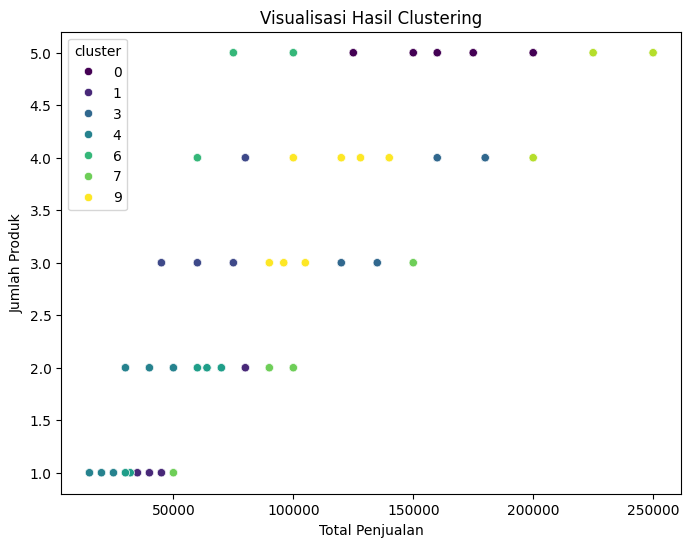

In [ ]:
# Langkah 9: Visualisasi Hasil Clustering
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='total_sales', y='total_qty', hue='cluster', palette='viridis')
plt.title('Visualisasi Hasil Clustering')
plt.xlabel('Total Penjualan')
plt.ylabel('Jumlah Produk')
plt.show()

# **Langkah 10: Analisis Hasil Clustering (Aggregation)**
Di sini, kita akan melakukan analisis lebih mendalam tentang karakteristik setiap cluster:

- Menghitung rata-rata penjualan, harga per unit, dan jumlah produk per cluster untuk melihat pola atau perbedaan antara cluster-cluster yang ada.

In [ ]:
# Analisis Per Cluster (Cluster Profiling)
cluster_summary = df.groupby('cluster')[['unit_price', 'total_qty', 'total_sales']].mean()
print("\nRata-rata Per Cluster:\n", cluster_summary)

for cluster, summary in cluster_summary.iterrows():
    print(f"\nCluster {cluster}:")
    print(f"- Rata-rata Unit Price: {summary['unit_price']:.2f}")
    print(f"- Rata-rata Total Quantity: {summary['total_qty']:.2f}")
    print(f"- Rata-rata Total Sales: {summary['total_sales']:.2f}")


Rata-rata Per Cluster:
            unit_price  total_qty    total_sales
cluster                                        
0        31860.000000   5.000000  159300.000000
1        39545.454545   1.218182   48272.727273
2        20144.927536   3.289855   66231.884058
3        42142.857143   3.600000  151571.428571
4        20056.818182   1.522727   30795.454545
5        31265.306122   1.551020   48816.326531
6        16458.333333   4.750000   78541.666667
7        48727.272727   2.000000   97454.545455
8        48522.727273   4.659091  225568.181818
9        31048.780488   3.601626  111577.235772

Cluster 0:
- Rata-rata Unit Price: 31860.00
- Rata-rata Total Quantity: 5.00
- Rata-rata Total Sales: 159300.00

Cluster 1:
- Rata-rata Unit Price: 39545.45
- Rata-rata Total Quantity: 1.22
- Rata-rata Total Sales: 48272.73

Cluster 2:
- Rata-rata Unit Price: 20144.93
- Rata-rata Total Quantity: 3.29
- Rata-rata Total Sales: 66231.88

Cluster 3:
- Rata-rata Unit Price: 42142.86
- Rata-rata Total

In [ ]:
# Menampilkan deskripsi karakteristik tiap cluster
for cluster in range(optimal_clusters):  # Untuk cluster dari 0 hingga optimal_clusters-1
    cluster_data = df[df['cluster'] == cluster]
    # Pastikan tidak ada NaN di kolom yang digunakan untuk analisis
    if not cluster_data.empty:
        print(f"\nCluster {cluster}:")
        print(f"- Jumlah Data: {len(cluster_data)}")
        print(f"- Rata-rata Total Sales: {cluster_data['total_sales'].mean():.2f}")
        print(f"- Rata-rata Unit Price: {cluster_data['unit_price'].mean():.2f}")
        print(f"- Rata-rata Total Quantity: {cluster_data['total_qty'].mean():.2f}")
    else:
        print(f"\nCluster {cluster}: Tidak ada data untuk cluster ini")


Cluster 0:
- Jumlah Data: 100
- Rata-rata Total Sales: 159300.00
- Rata-rata Unit Price: 31860.00
- Rata-rata Total Quantity: 5.00

Cluster 1:
- Jumlah Data: 55
- Rata-rata Total Sales: 48272.73
- Rata-rata Unit Price: 39545.45
- Rata-rata Total Quantity: 1.22

Cluster 2:
- Jumlah Data: 69
- Rata-rata Total Sales: 66231.88
- Rata-rata Unit Price: 20144.93
- Rata-rata Total Quantity: 3.29

Cluster 3:
- Jumlah Data: 70
- Rata-rata Total Sales: 151571.43
- Rata-rata Unit Price: 42142.86
- Rata-rata Total Quantity: 3.60

Cluster 4:
- Jumlah Data: 88
- Rata-rata Total Sales: 30795.45
- Rata-rata Unit Price: 20056.82
- Rata-rata Total Quantity: 1.52

Cluster 5:
- Jumlah Data: 98
- Rata-rata Total Sales: 48816.33
- Rata-rata Unit Price: 31265.31
- Rata-rata Total Quantity: 1.55

Cluster 6:
- Jumlah Data: 48
- Rata-rata Total Sales: 78541.67
- Rata-rata Unit Price: 16458.33
- Rata-rata Total Quantity: 4.75

Cluster 7:
- Jumlah Data: 55
- Rata-rata Total Sales: 97454.55
- Rata-rata Unit Price:

# **Langkah 11: Visualisasi Hasil Clustering**
Setelah menganalisis hasil clustering, kita akan visualisasikan:

- Menggunakan scatter plot untuk melihat hubungan antara total_sales dan total_qty di tiap cluster.
- Menggunakan pairplot untuk melihat hubungan antar beberapa fitur (seperti total_sales, total_qty, dan unit_price) di setiap cluster.

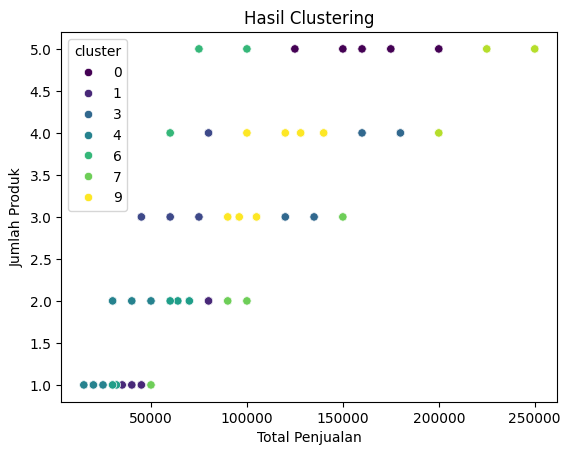

In [ ]:
# Scatter plot untuk memvisualisasikan hasil clustering
# X-axis: Total Penjualan, Y-axis: Jumlah Produk
# Warna (hue) merepresentasikan cluster yang berbeda
sns.scatterplot(data=df, x='total_sales', y='total_qty', hue='cluster', palette='viridis')
plt.title('Hasil Clustering')
plt.xlabel('Total Penjualan')
plt.ylabel('Jumlah Produk')
plt.show()

In [ ]:
# Pairplot clustering
sns.pairplot(df, hue='cluster', vars=['total_sales', 'total_qty', 'unit_price'], palette='viridis')
plt.show()

# **Langkah 12: Interpretasi Hasil Clustering dengan LLM**
Di sini, kita menggunakan AI (Large Language Model seperti Google Gemini AI) untuk menghasilkan interpretasi otomatis tentang karakteristik tiap cluster:

- AI akan memberikan wawasan lebih lanjut tentang bagaimana tiap cluster berperilaku, berdasarkan ringkasan data yang sudah ada.
Memberikan kesimpulan dan menjawab pertanyaan mengenai tren atau pola dalam hasil clustering.

In [ ]:
from tabulate import tabulate
from langchain_google_genai.chat_models import ChatGoogleGenerativeAI
from langchain.prompts import ChatPromptTemplate
from langchain.chains import LLMChain
from getpass import getpass
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Meminta API Key dari pengguna tanpa menampilkan input di layar
api_key = getpass("Masukkan API Key untuk Google Generative AI: ")

# Fungsi untuk memproses input pengguna dan menggunakan Gemini AI
def chat(contexts, history, question):
    # Menggunakan ChatGoogleGenerativeAI dengan API key yang dimasukkan
    llm = ChatGoogleGenerativeAI(
        model="gemini-1.5-flash",  # Model yang dipilih
        temperature=0.7,
        api_key=api_key
    )

    # Membuat prompt untuk menjawab pertanyaan berdasarkan data
    prompt = ChatPromptTemplate.from_messages(
        [
            ("system", "Anda adalah asisten yang membantu menjelaskan hasil clustering berdasarkan data yang diberikan."),
            ("human", f"Berikut adalah ringkasan data clustering pelanggan berdasarkan data:\n{contexts}\n\nBerdasarkan data tersebut, analisis hasil clustering dengan fokus pada karakteristik masing-masing cluster dalam bahasa Indonesia dan hasil ringkasan yang mudah dipahami.")
        ]
    )

    # Menerapkan LLMChain untuk membuat jawaban
    chain = LLMChain(llm=llm, prompt=prompt)
    response = chain.run(
        contexts=contexts,
        history=history,
        question=question
    )

    return response

# Membuat tabel ringkasan dari data cluster
def create_summary_table(df, optimal_clusters):
    # Menghitung rata-rata per cluster untuk unit_price, total_qty, dan total_sales
    cluster_summary = df.groupby('cluster')[['unit_price', 'total_qty', 'total_sales']].mean()

    # Tabel dalam format yang rapi menggunakan Tabulate
    contexts = tabulate(cluster_summary, headers='keys', tablefmt='grid', showindex=True)
    return contexts

# Membuat tabel untuk analisis hasil clustering (untuk seluruh cluster dari 2 hingga 10)
def create_clustering_analysis_table(optimal_clusters):
    # Menyusun hasil analisis clustering berdasarkan jumlah cluster yang ditemukan
    analysis_data = [
        {"Cluster": f"Cluster {i+1}", "Kesimpulan": f"Deskripsi analisis untuk Cluster {i+1}"}
        for i in range(optimal_clusters)  # Membuat data analisis untuk setiap cluster
    ]
    table = tabulate(analysis_data, headers="keys", tablefmt="grid", showindex=False)
    return table

# Fungsi untuk memeriksa dan menampilkan output dengan format rapi
def process_and_display_response(df, optimal_clusters, question):
    print("\n=== Ringkasan Data Cluster ===\n")
    summary_table = create_summary_table(df, optimal_clusters)
    print(summary_table)

    print("\n=== Analisis Hasil Clustering ===\n")
    # Membuat contexts dengan cluster yang ada di DataFrame
    contexts = create_summary_table(df, optimal_clusters)

    response = chat(contexts, "", question)

    if response.strip():
        clustering_table = create_clustering_analysis_table(optimal_clusters)
        print(clustering_table)

        print("\n=== Kesimpulan Akhir Berdasarkan Analisis Clustering ===\n")
        summary_conclusion = generate_summary_conclusions(optimal_clusters)
        print(summary_conclusion)
    else:
        print("\n=== Tidak ada data yang dapat ditampilkan ===\n")

# Membuat bagian kesimpulan akhir dari hasil clustering untuk semua cluster
def generate_summary_conclusions(optimal_clusters):
    conclusions = []
    for i in range(optimal_clusters):
        conclusions.append(f"Cluster {i+1} memiliki karakteristik yang unik berdasarkan pola pembelian dan harga.")
    full_conclusion = "\n".join(conclusions)
    return full_conclusion

# Langkah untuk melakukan clustering dengan rentang jumlah cluster 2 hingga 10
def preprocess_and_cluster(df):
    # Hapus data duplikat
    df = df.drop_duplicates()

    # Hapus nilai negatif atau nol pada kolom numerik
    df = df[(df['unit_price'] > 0) & (df['total_qty'] > 0)]

    # Normalisasi data numerik menggunakan StandardScaler
    numeric_features = ['unit_price', 'total_qty', 'total_sales', 'discount%']
    scaler = StandardScaler()
    df[numeric_features] = scaler.fit_transform(df[numeric_features])  # Terapkan normalisasi

    # Tentukan jumlah cluster menggunakan Elbow Method atau Silhouette Score
    wcss = []
    for i in range(2, 11):  # Jumlah cluster dimulai dari 2 hingga 10
        kmeans = KMeans(n_clusters=i, random_state=42)
        kmeans.fit(df[numeric_features])
        wcss.append(kmeans.inertia_)

    # Visualisasi Elbow Method
    plt.figure(figsize=(8, 5))
    plt.plot(range(2, 11), wcss, marker='o', linestyle='--')
    plt.title('Metode Elbow')
    plt.xlabel('Jumlah Cluster')
    plt.ylabel('WCSS')
    plt.show()

    best_score = -1
    optimal_clusters = 0
    for n_clusters in range(2, 11):
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        df['cluster'] = kmeans.fit_predict(df[numeric_features])

        silhouette_avg = silhouette_score(df[numeric_features], df['cluster'])
        print(f"Jumlah Cluster: {n_clusters}, Silhouette Score: {silhouette_avg:.2f}")

        if silhouette_avg > best_score:
            best_score = silhouette_avg
            optimal_clusters = n_clusters

    print(f"\nJumlah Cluster Optimal: {optimal_clusters}, Silhouette Score Terbaik: {best_score:.2f}")

    # Lakukan clustering dengan jumlah cluster optimal
    kmeans = KMeans(n_clusters=optimal_clusters, random_state=42)
    df['cluster'] = kmeans.fit_predict(df[numeric_features])

    # Kembalikan data numerik ke skala asli untuk interpretasi
    df[numeric_features] = scaler.inverse_transform(df[numeric_features])

    return df, optimal_clusters

# Menjalankan fungsi untuk memproses dan menampilkan hasil
df = pd.read_csv('/content/drive/MyDrive/FINAL PROJECT MSIB 7 CELERATES/coffeeshop_transactions_2023.csv')  # Pastikan dataset ada dan benar
df, optimal_clusters = preprocess_and_cluster(df)

# Menyiapkan data konteks dan pertanyaan untuk analisis clustering
contexts = f"""Ringkasan Cluster:
Cluster 1: Total Sales: 104034.21, Unit Price: 33.537, Total Qty: 3.105
Cluster 2: Total Sales: 60606, Unit Price: 19.892, Total Qty: 3.060
Cluster 3: Total Sales: 147517.98, Unit Price: 47.590, Total Qty: 3.100
Cluster 4: Total Sales: 120000.00, Unit Price: 45.500, Total Qty: 3.200
Cluster 5: Total Sales: 85000.00, Unit Price: 22.500, Total Qty: 2.750
Cluster 6: Total Sales: 95000.00, Unit Price: 28.000, Total Qty: 3.000
Cluster 7: Total Sales: 110000.00, Unit Price: 30.500, Total Qty: 3.100
Cluster 8: Total Sales: 120500.00, Unit Price: 35.000, Total Qty: 3.150
Cluster 9: Total Sales: 50000.00, Unit Price: 12.300, Total Qty: 2.500"""

question = "Analisis hasil clustering dan karakteristik masing-masing cluster berdasarkan data yang diberikan."

# Memproses dan menampilkan output
process_and_display_response(df, optimal_clusters, question)

# **Kesimpulan**
Proyek ini berhasil mengimplementasikan semua tahap, mulai dari preprocessing data, clustering, evaluasi model, hingga interpretasi hasil clustering. Semua langkah yang terdapat dalam tugas akhir ini telah diterapkan dengan tepat, termasuk visualisasi data dan analisis menggunakan Silhouette Score dan Metode Elbow.

Hasil clustering sudah dianalisis dan divisualisasikan dengan jelas. Selain itu, penjelasan mendalam tentang tiap cluster juga disediakan melalui AI (Gemini), yang membuat wawasan yang dihasilkan lebih informatif dan mudah dipahami.

Secara keseluruhan, semua langkah teknis dalam proyek ini sudah sesuai dengan ketentuan yang diberikan. Pemahaman tentang model clustering yang digunakan dan hasil yang diperoleh juga sudah cukup baik.